alpha (V = K * I^alpha) = 0.07818
K (kV/A^alpha)         = 53.54084


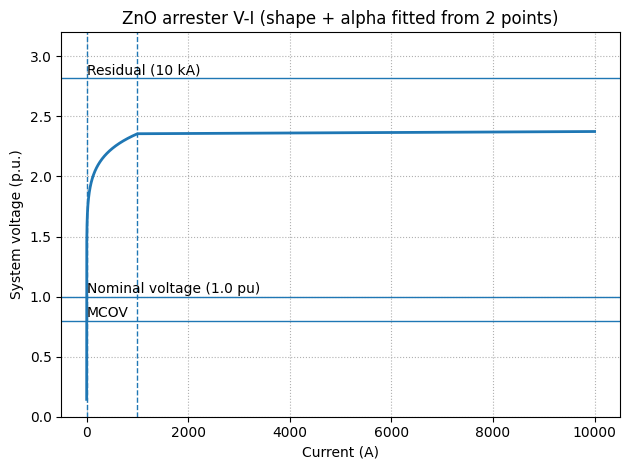

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Input data (from your table)
# -----------------------------
Un_kV = 39.0       # Rated voltage (kV)
MCOV_kV = 31.2     # MCOV (kV)
I_nom_A = 10_000.0 # Nominal discharge current (A) = 10 kA
U_res_kV = 110.0   # Max residual voltage at I_nom (kV)

# ---------------------------------------------------------
# Second point assumption (needed to fit alpha from 2 points)
# Assumption: at 1 mA, voltage ~ MCOV (practical approximation)
# Replace V1_kV with U1mA_kV if you have it from datasheet.
# ---------------------------------------------------------
I1_A = 1e-3
V1_kV = MCOV_kV

I2_A = I_nom_A
V2_kV = U_res_kV

# -----------------------------
# Fit power-law: V = K * I^alpha
# -----------------------------
alpha = np.log(V2_kV / V1_kV) / np.log(I2_A / I1_A)
K = V2_kV / (I2_A ** alpha)

print(f"alpha (V = K * I^alpha) = {alpha:.5f}")
print(f"K (kV/A^alpha)         = {K:.5f}")

# ---------------------------------------------------------
# Build a "figure-like" curve using 3 regions (convenient)
# Region 1: low-current (steeper)
# Region 2: highly nonlinear (fitted alpha)
# Region 3: high-current (adds dynamic resistance for upturn)
# ---------------------------------------------------------
I = np.logspace(-4, 4, 2000)  # 1e-4 A to 1e4 A

# Region boundaries (chosen to resemble typical plot)
I_a = 0.1     # boundary to highly nonlinear region (A)
I_b = 1000.0  # boundary to upper region (A)

# Region 2 (fitted)
V2_fit_kV = K * (I ** alpha)

# Region 1: make it steeper below I_a (convenient shaping)
# Ensure continuity at I_a
V_a_kV = K * (I_a ** alpha)
alpha_low = 0.30
K_low = V_a_kV / (I_a ** alpha_low)
V_low_kV = K_low * (I ** alpha_low)

# Region 3: add dynamic resistance effect above I_b
# Ensure continuity at I_b
V_b_kV = K * (I_b ** alpha)
r_dyn_kV_per_A = 0.00008  # 0.08 kV/kA (convenient)
V_high_kV = V_b_kV + r_dyn_kV_per_A * (I - I_b)

# Combine piecewise
V_kV = np.where(I < I_a, V_low_kV, V2_fit_kV)
V_kV = np.where(I > I_b, V_high_kV, V_kV)

# Convert to per-unit (based on Un, to match the style of the figure)
V_pu = V_kV / Un_kV

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots()

ax.semilogx(I, V_pu, linewidth=2.0)

# Reference horizontal lines (similar to the figure)
ax.axhline(Un_kV / Un_kV, linewidth=1.0)              # 1.0 pu
ax.axhline(MCOV_kV / Un_kV, linewidth=1.0)            # MCOV in pu
ax.axhline(U_res_kV / Un_kV, linewidth=1.0)           # residual at 10 kA in pu

# Vertical dashed separators
ax.axvline(I_a, linestyle="--", linewidth=1.0)
ax.axvline(I_b, linestyle="--", linewidth=1.0)

ax.set_xlabel("Current (A)")
ax.set_ylabel("System voltage (p.u.)")
ax.set_title("ZnO arrester V-I (shape + alpha fitted from 2 points)")

ax.set_ylim(0.0, max(3.2, np.max(V_pu) * 1.05))
ax.grid(True, which="both", linestyle=":")

# Annotate key levels
ax.text(2e-4, Un_kV / Un_kV + 0.03, "Nominal voltage (1.0 pu)")
ax.text(2e-4, MCOV_kV / Un_kV + 0.03, "MCOV")
ax.text(2e-4, U_res_kV / Un_kV + 0.03, "Residual (10 kA)")

plt.tight_layout()
plt.show()
